## Description

The goal of this notebook is to predict the strains' phenotype based on VEPs and FungAMR confidence scores. This is ML.

I use Repeated Nested Cross-Validation (CV), which combines Repeated CV and Nested CV.

The Repeated CV is done to estimate the variability of the predictions. It's simply rerunning standard k-fold cross-validation multiple times with different splits of the dataset. By doing that, we avoid overestimating or underestimating our performance just because of a lucky or unlucky split. 

The Nested Cross-validation is done to select hyperparameters. It uses two loops: an inner loop to select the best parameters and an outer loop to test how well the model works on new data. By doing that, we avoid overfitting the data.

The combination of the two leads to a really long code... (sorry) ! (RepeatedStratifiedKFold exists, but not RepeatedGroupStratifiedKFold, so I had to code a function looping repeats).

In [1]:
#Load packages
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np
from collections import defaultdict
from functools import reduce

import shap
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, StratifiedGroupKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_score, recall_score, balanced_accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier



In [2]:
#Dictionnary to map gene names
gene_map = {"C3_05780C_A": "Crz1","C5_00660C_A": "Cyp51","C3_05920W_A": "Mrr1","C3_04890W_A": "Cdr2","C4_01260W_A": "Rlm1","C5_03390C_A": "Fur1",
    "C1_08460C_A": "Upc2","CR_00850C_A": "Fks2","C5_01840C_A": "Tac1","C3_05220W_A": "Cdr1","CR_00120C_A": "Mkc1","C1_02420C_A": "Fks",
    "C1_00730C_A": "Cmp1","C1_04770C_A": "Erg3","C1_01790W_A": "Swi4","C6_03170C_A": "Ben1","C2_03160C_A": "Rnr1","C3_02220W_A": "Cap1",
    "C3_07860C_A": "Mrr2","C2_06470W_A": "Rta2","C1_00800C_A": "Erg2","C1_08590C_A": "Erg1","C2_03010C_A": "Rnr21",
    "C5_05160C_A": "Cnb1","C2_05780C_A": "Mkk2","C2_06460W_A": "Rta3","C2_07940C_A": "Alg7", "C6_00620W_A":"Fca1"}

In [3]:
#Load datasets, it takes a few sec to run
df_foldx1 = pd.read_csv("mutateX_gwas.csv") #Initial FoldX data
df_foldx_new = pd.read_csv("mutatex_results_new_prots_01_2026.csv") #Additional FoldX data
df_esm = pd.read_csv("esm_albicans_fungAMR_genes.csv") #Initial ESM data
df_esm_miss = pd.read_csv("esm_scores_missing_prot_calbicans.csv", sep=";") #Additional ESM data
df_gemme = pd.read_csv("gemme_albicans.csv") #GEMME data
df = pd.read_csv("FungAMR_Calbicans_SNP_merge_all_vcf_missense_16042026.csv", low_memory=False) #SNPs df merged with FungAMR data, heavy
df_clus = pd.read_excel("cluster_assignement.xlsx") #df with PCA phylogenetic clusters

In [4]:
#Define seed to be used accross all the notebook

seed=276  #a cool number, random states used in code = seed + repeat + 100 (377, 479, 582, 686 and 791), 

#I learned that using consecutive seeds was not a good idea, so that's why I add repeat + 100 to the initial seed number

## Dataframes setup

#### SNPs, FungAMR and phenotypes

In [5]:
##Pivot the df, it runs for a long time 

#Filter
df = df[~df['Study'].isin(['Chew2021', 'Gong2023'])] #remove studies in FungAMR
df = df[~df['SampleID'].isin(['31495Z', '14031008HVS', 'BL118prothese', "BL015", "BL050"])] #remove non albicans samples

#Columns to keep 
rbin_cols = [c for c in df.columns if c.startswith("rbin_")]
base_cols = ["SampleID", "Study", "mutation", "drug", "Adarsh_phenotype", "gene_name",
             "Strongest resistance evidence reported", "Strongest sensitivity evidence reported"]
df_small = df[base_cols + rbin_cols].copy()

#Rename
df_small = df_small.rename(columns={"Strongest resistance evidence reported": "resistance", "Strongest sensitivity evidence reported": "sensitivity"})

#SampleID–mutation pairs
full_idx = (df_small[["SampleID", "mutation", "gene_name"]]
    .drop_duplicates()
    .set_index(["SampleID", "mutation", "gene_name"]).index)

#Pivot
df_pivot = df_small.pivot_table(index=["SampleID", "mutation","gene_name"],
    columns="drug",
    values=["resistance", "sensitivity"],
    aggfunc="max",
    dropna=False).reindex(full_idx)

#Reset index
df_pivot = df_pivot.reset_index()

#Flatten
df_pivot.columns = ["_".join([str(c) for c in col if c not in (None, "", "nan", float("nan"))])
    if isinstance(col, tuple) else str(col) for col in df_pivot.columns]

#Phenotype 
phen = (df_small[["SampleID", "Adarsh_phenotype"]].dropna(subset=["Adarsh_phenotype"]).drop_duplicates(subset=["SampleID"]))

#Merge phenotype 
df_pivot = df_pivot.merge(phen, on="SampleID", how="left")

#One row per SampleID for rbin
rbin_cols = [col for col in df_small.columns if col.startswith("rbin")]
rbin_map = df_small[["SampleID"] + rbin_cols].drop_duplicates(subset=["SampleID"])

#Merge rbin columns 
df_piv = df_pivot.merge(rbin_map, on="SampleID", how="left")
df_piv["gene_name"] = df_piv["gene_name"].replace(gene_map) 

all_genes = df_piv["gene_name"].unique().tolist()

df_piv

,SampleID,mutation,gene_name,resistance_5-fluorocytosine,resistance_Amphotericin B,resistance_Anidulafungin,resistance_Brefeldin A,resistance_Caspofungin,resistance_Cerulenin,resistance_Clotrimazole,...,Adarsh_phenotype,rbin_5FC,rbin_ampB,rbin_flu,rbin_vor,rbin_pos,rbin_itra,rbin_cas,rbin_ani,rbin_mic
0,63697ECS,R601K,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
1,63697ECS,V598I,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
2,BL286,P597L,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
3,MYC-19-0073,V524G,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,NaN,S,S,NaN,NaN,NaN,NaN,NaN,S
4,BL144,M510I,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51045,1434932HVS,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
51046,3634HVS,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,NaN,NaN,S,NaN,NaN,NaN,NaN,NaN,NaN
51047,CALB0386,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,S,S,S,S,S,S,S,S,S
51048,CALB0588,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,NaN,NaN,S,NaN,NaN,NaN,S,NaN,NaN


In [6]:
#Add the PCA clusters to the df
df_piv = df_piv.merge(df_clus, on="SampleID", how="left")
df_piv = df_piv[df_piv["SampleID"].isin(df_clus["SampleID"])]
df_piv

,SampleID,mutation,gene_name,resistance_5-fluorocytosine,resistance_Amphotericin B,resistance_Anidulafungin,resistance_Brefeldin A,resistance_Caspofungin,resistance_Cerulenin,resistance_Clotrimazole,...,original_sample_name,study,pca_cluster,pca_cluster_label,fluconazole,voriconazole,posaconazole,caspofungin,anidulafungin,micafungin
0,63697ECS,R601K,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,63697ECS_ChampignonsMay2024,Our Study,12.0,C12,NaN,NaN,NaN,NaN,NaN,NaN
1,63697ECS,V598I,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,63697ECS_ChampignonsMay2024,Our Study,12.0,C12,NaN,NaN,NaN,NaN,NaN,NaN
2,BL286,P597L,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,BL286_ChampignonsMay2024,Our Study,11.0,C11,NaN,NaN,NaN,NaN,NaN,NaN
3,MYC-19-0073,V524G,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,MYC-19-0073,Our Study,13.0,C13,S,NaN,NaN,NaN,NaN,S
4,BL144,M510I,Cmp1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,BL144_ChampignonsMay2024,Our Study,23.0,C23,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51045,1434932HVS,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1434932HVS_ChampignonsMay2024,Our Study,19.0,C19,NaN,NaN,NaN,NaN,NaN,NaN
51046,3634HVS,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3634HVS_ChampignonsMay2024,Our Study,19.0,C19,NaN,NaN,NaN,NaN,NaN,NaN
51047,CALB0386,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,CALB0386_ERR4669759,Szarvas2021,19.0,C19,S,S,S,S,S,S
51048,CALB0588,T13A,Fks2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,CALB0588_SRR6669961,Sitterle2020,19.0,C19,S,NaN,NaN,S,NaN,NaN


In [7]:
#List of drugs 
drugs = ["Anidulafungin", "Caspofungin", "Fluconazole", "Isavuconazole", "Itraconazole", "Micafungin", "Posaconazole", "Voriconazole"]

#Keep only relevant columns
base_cols = ["SampleID", "mutation","gene_name"]
rbin_cols = [col for col in df_piv.columns if col.startswith("rbin_")]
wanted_cols = ["pca_cluster_label", "Adarsh_phenotype"]

for drug in drugs:
    wanted_cols.append(f"resistance_{drug}")
    wanted_cols.append(f"sensitivity_{drug}")

df_filtered = df_piv[base_cols + rbin_cols+ wanted_cols ].copy()

#overall score
for drug in drugs:
    res_col = f"resistance_{drug}"
    susc_col = f"sensitivity_{drug}"
    overall_col = f"{drug}_overall_score"

    res = df_filtered[res_col]
    susc = df_filtered[susc_col]

    #Start with NaNs
    overall = pd.Series(np.nan, index=df_filtered.index)

    #both present ??
    both_present = res.notna() & susc.notna()
    res_vals = res[both_present]
    susc_vals = susc[both_present]

    #If abs(resistance) < abs(sensitivity), choose resistance
    #If abs(sensitivity) < abs(resistance), choose sensitivity
    #If equal, prefer resistance
    overall[both_present] = np.where(
        abs(res_vals) < abs(susc_vals), res_vals,
        np.where(abs(susc_vals) < abs(res_vals), susc_vals, res_vals))

    only_res = res.notna() & susc.isna()
    overall[only_res] = res[only_res]

    only_susc = susc.notna() & res.isna()
    overall[only_susc] = susc[only_susc]

    df_filtered[overall_col] = overall

df_filtered.loc[df_filtered["mutation"] == "V488I", ["Posaconazole_overall_score", "Voriconazole_overall_score"]] = 8  #error in the database

df_filtered["gene_name"] = df_filtered["gene_name"].replace(gene_map) 

df_filtered

,SampleID,mutation,gene_name,rbin_5FC,rbin_ampB,rbin_flu,rbin_vor,rbin_pos,rbin_itra,rbin_cas,...,resistance_Voriconazole,sensitivity_Voriconazole,Anidulafungin_overall_score,Caspofungin_overall_score,Fluconazole_overall_score,Isavuconazole_overall_score,Itraconazole_overall_score,Micafungin_overall_score,Posaconazole_overall_score,Voriconazole_overall_score
0,63697ECS,R601K,Cmp1,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,63697ECS,V598I,Cmp1,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BL286,P597L,Cmp1,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MYC-19-0073,V524G,Cmp1,NaN,S,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BL144,M510I,Cmp1,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51045,1434932HVS,T13A,Fks2,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51046,3634HVS,T13A,Fks2,NaN,NaN,S,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51047,CALB0386,T13A,Fks2,S,S,S,S,S,S,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51048,CALB0588,T13A,Fks2,NaN,NaN,S,NaN,NaN,NaN,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### VEPs

In [8]:
#Prepare df_foldx
#get all the foldX data in a single df
df_foldx1 = df_foldx1.rename(columns={"Gene ID": "gene_name"})
df_foldx_new = df_foldx_new.rename(columns={"Gene ID": "gene_name"})
df_foldx = pd.concat([df_foldx1, df_foldx_new],axis=0,ignore_index=True)

df_foldx = df_foldx[["mutation", "gene_name", "ddG"]].copy()
df_foldx["gene_name"] = (df_foldx["gene_name"].astype(str).str.replace("\xa0", " ", regex=False).replace(gene_map))
df_foldx["gene_name"].unique()
df_foldx

,mutation,gene_name,ddG
0,M1G,CR_04090C_A,-0.06621
1,S2G,CR_04090C_A,0.20383
2,D3G,CR_04090C_A,-0.10389
3,K4G,CR_04090C_A,0.70455
4,Q5G,CR_04090C_A,0.20027
...,...,...,...
1139535,R605H,Cmp1,0.67725
1139536,L606H,Cmp1,1.21111
1139537,S607H,Cmp1,0.36598
1139538,Q608H,Cmp1,-0.02029


In [9]:
#Prepare df_esm
df_esm = df_esm[["mutation", "gene_name", "esm_score"]].copy()
df_esm_miss = df_esm_miss.rename(columns={"ortho_homolog": "gene_name"})
df_esm["gene_name"] = df_esm["gene_name"].replace(gene_map)
df_esm_miss = df_esm_miss[["mutation", "gene_name", "esm_score"]].copy()

#Combine
df_esm = pd.concat([df_esm, df_esm_miss], ignore_index=True)
df_esm

,mutation,gene_name,esm_score
0,M1K,Alg7,-8.153466
1,M1R,Alg7,-7.999102
2,M1H,Alg7,-9.168739
3,M1E,Alg7,-8.811132
4,M1D,Alg7,-9.094440
...,...,...,...
425035,T1017M,Swi4,-3.677284
425036,T1017P,Swi4,-4.484548
425037,T1017Y,Swi4,-2.549129
425038,T1017F,Swi4,-3.147504


In [10]:
#Prepare df_gemme
df_gemme = df_gemme[["mutation", "gemme", "ortho_homolog"]].copy()
df_gemme = df_gemme.rename(columns={"ortho_homolog": "gene_name"})
df_gemme["gene_name"].unique()

array(['Ben1', 'Upc2', 'Erg2', 'Rnr21', 'Cdr2', 'Rta2', 'Erg1', 'Fks',
       'Fur1', 'Swi4', 'Rlm1', 'Mkc1', 'Cnb1', 'Cyp51', 'Mrr2', 'Mkk2',
       'Rta3', 'Alg7', 'Crz1', 'Tac1', 'Rnr1', 'Cap1', 'Mrr1', 'Cmp1',
       'Erg3', 'Cdr1'], dtype=object)

#### Merge all

In [11]:
#Merge all the datasets
df_merged = df_esm.merge(df_filtered,on=["mutation", "gene_name"],how="inner")
df_merged2 = df_foldx.merge(df_merged,on=["mutation", "gene_name"],how="inner")
df_merged2["gene_name"] = df_merged2["gene_name"].replace(gene_map)
df_all = df_gemme.merge(df_merged2,on=["mutation", "gene_name"],how="inner")

df_all

,mutation,gemme,gene_name,ddG,esm_score,SampleID,rbin_5FC,rbin_ampB,rbin_flu,rbin_vor,...,resistance_Voriconazole,sensitivity_Voriconazole,Anidulafungin_overall_score,Caspofungin_overall_score,Fluconazole_overall_score,Isavuconazole_overall_score,Itraconazole_overall_score,Micafungin_overall_score,Posaconazole_overall_score,Voriconazole_overall_score
0,D32N,-0.551997,Ben1,0.05657,-3.933850,1294954HVS,NaN,NaN,S,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,D32N,-0.551997,Ben1,0.05657,-3.933850,12,R,S,R,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,D32N,-0.551997,Ben1,0.05657,-3.933850,25753,NaN,S,R,R,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,D32N,-0.551997,Ben1,0.05657,-3.933850,31309,S,S,R,R,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D32N,-0.551997,Ben1,0.05657,-3.933850,36800,S,S,S,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45553,F1467L,-0.651086,Cdr1,0.68120,-4.301130,MYC-19-0075,NaN,S,S,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45554,F1467L,-0.651086,Cdr1,0.68120,-4.301130,MYC-19-0247,NaN,S,S,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45555,L1480F,-0.614902,Cdr1,0.59836,-4.158593,52,R,S,R,R,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45556,L1480F,-0.614902,Cdr1,0.59836,-4.158593,MYC-19-0248,NaN,S,S,S,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df_all["gene_name"].unique()

array(['Ben1', 'Upc2', 'Erg2', 'Cdr2', 'Rta2', 'Erg1', 'Fks', 'Fur1',
       'Swi4', 'Rlm1', 'Mkc1', 'Cnb1', 'Cyp51', 'Mrr2', 'Mkk2', 'Crz1',
       'Tac1', 'Rnr1', 'Cap1', 'Mrr1', 'Cmp1', 'Erg3', 'Cdr1'],
      dtype=object)

In [13]:
##Separate in different types
df_filtered = df_all.copy()

#Litterature
df_filtered_all = df_filtered[df_filtered["Adarsh_phenotype"] != True].copy()

#Strains we have in the lab
df_filtered_all_valid = df_filtered[df_filtered["Adarsh_phenotype"] == True].copy()

In [14]:
#Genes in the initial dfs but missing from each dataframe (and so missing of df_all also)
missing_in_esm = set(all_genes) - set(df_esm["gene_name"].unique())
missing_in_foldx = set(all_genes) - set(df_foldx["gene_name"].unique())
missing_in_gemme = set(all_genes) - set(df_gemme["gene_name"].unique())

print("Genes missing from df_esm:", missing_in_esm)
print("Genes missing from df_foldx:", missing_in_foldx)
print("Genes missing from df_gemme:", missing_in_gemme)

Genes missing from df_esm: set()
Genes missing from df_foldx: {'Rnr21'}
Genes missing from df_gemme: {'Fks2'}


In [15]:
# Unique gene-mutation combinations
df_all['gene_mutation'] = df_all['gene_name'] + "_" + df_all['mutation']
num_pairs = df_all['gene_mutation'].nunique()
print(f"Unique gene-mutation pairs: {num_pairs}")

Unique gene-mutation pairs: 1292


In [16]:
#Create gene-mutation pair
df_all['gene_mutation'] = df_all['gene_name'] + "_" + df_all['mutation']

#Create a dictionary mapping SampleID 
sample_to_pairs = df_all.groupby('SampleID')['gene_mutation'].apply(list).to_dict()

In [17]:
# Each gene is a feature with the score, when no mut score = 0 automatically since WT (gemme, esm and foldx = wt-like when 0)
#Aggregate 
agg_df = (df_filtered_all.groupby(["SampleID", "gene_name", "pca_cluster_label"])
    .agg(esm_score_min=("esm_score", "min"), ddG_max=("ddG", "max"), gemme_min=("gemme", "min"), rbin_flu=("rbin_flu", "first")).reset_index())

#Pivot so each gene gets its own set of columns
wide_df = agg_df.pivot_table(index=["SampleID", "pca_cluster_label","rbin_flu"],
    columns="gene_name", values=["esm_score_min", "ddG_max","gemme_min"])

#Flatten 
wide_df.columns = [f"{gene}_{stat}" for stat, gene in wide_df.columns]

wide_df = wide_df.reset_index().fillna(0)
wide_df

,SampleID,pca_cluster_label,rbin_flu,Ben1_ddG_max,Cap1_ddG_max,Cdr1_ddG_max,Cdr2_ddG_max,Cmp1_ddG_max,Cnb1_ddG_max,Crz1_ddG_max,...,Mkc1_gemme_min,Mkk2_gemme_min,Mrr1_gemme_min,Mrr2_gemme_min,Rlm1_gemme_min,Rnr1_gemme_min,Rta2_gemme_min,Swi4_gemme_min,Tac1_gemme_min,Upc2_gemme_min
0,10,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
1,11,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
2,12,C13,R,2.66769,-0.00618,0.55438,1.26630,0.00000,0.0,1.31428,...,0.000000,0.0,-0.706195,-1.606078,-1.273347,0.00000,0.000000,0.000000,-0.657407,-0.145595
3,13,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.649549,-4.706017
4,14,C11,R,-1.22461,0.00000,0.10875,2.18000,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.318087
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482,MYC-19-0375,C11,R,-1.22461,3.14543,0.10875,1.26630,-0.19399,0.0,0.41184,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.133083
483,MYC-19-0376,C4,R,0.10707,0.68126,3.35436,1.26630,0.00000,0.0,0.41184,...,0.000000,0.0,0.000000,-1.606078,-2.283397,0.00000,0.000000,-2.336425,-0.260919,-1.873710
484,MYC-19-0387,C11,R,-1.22461,0.00000,1.07628,2.76699,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.869529,-4.706017
485,MYC-19-2,C6,S,-1.22461,0.00000,3.35436,17.90844,0.28188,0.0,0.06264,...,0.000000,0.0,0.000000,-0.469131,-1.273347,-0.07259,0.000000,-2.835305,-0.260919,0.006437


In [18]:
#remove samples that have the same mutations since they would be identical and lead to leakage
wide_df = wide_df.drop_duplicates(subset=[col for col in wide_df.columns if col not in ["SampleID", "pca_cluster_label"]], keep="first")

wide_df

,SampleID,pca_cluster_label,rbin_flu,Ben1_ddG_max,Cap1_ddG_max,Cdr1_ddG_max,Cdr2_ddG_max,Cmp1_ddG_max,Cnb1_ddG_max,Crz1_ddG_max,...,Mkc1_gemme_min,Mkk2_gemme_min,Mrr1_gemme_min,Mrr2_gemme_min,Rlm1_gemme_min,Rnr1_gemme_min,Rta2_gemme_min,Swi4_gemme_min,Tac1_gemme_min,Upc2_gemme_min
0,10,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
1,11,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
2,12,C13,R,2.66769,-0.00618,0.55438,1.26630,0.00000,0.0,1.31428,...,0.000000,0.0,-0.706195,-1.606078,-1.273347,0.00000,0.000000,0.000000,-0.657407,-0.145595
3,13,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.649549,-4.706017
4,14,C11,R,-1.22461,0.00000,0.10875,2.18000,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.318087
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482,MYC-19-0375,C11,R,-1.22461,3.14543,0.10875,1.26630,-0.19399,0.0,0.41184,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.133083
483,MYC-19-0376,C4,R,0.10707,0.68126,3.35436,1.26630,0.00000,0.0,0.41184,...,0.000000,0.0,0.000000,-1.606078,-2.283397,0.00000,0.000000,-2.336425,-0.260919,-1.873710
484,MYC-19-0387,C11,R,-1.22461,0.00000,1.07628,2.76699,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.869529,-4.706017
485,MYC-19-2,C6,S,-1.22461,0.00000,3.35436,17.90844,0.28188,0.0,0.06264,...,0.000000,0.0,0.000000,-0.469131,-1.273347,-0.07259,0.000000,-2.835305,-0.260919,0.006437


In [19]:
#Keep only PCA clusters with more than 5 samples (since we do k=5)
enough_clusters = wide_df["pca_cluster_label"].value_counts()
enough_clusters = enough_clusters[enough_clusters > 15].index

wide_df = wide_df[wide_df["pca_cluster_label"].isin(enough_clusters)].copy()

print(wide_df["pca_cluster_label"].value_counts())

pca_cluster_label
C11    180
C9      49
C1      48
C13     36
C6      33
C14     20
C3      16
Name: count, dtype: int64


In [20]:
wide_df

,SampleID,pca_cluster_label,rbin_flu,Ben1_ddG_max,Cap1_ddG_max,Cdr1_ddG_max,Cdr2_ddG_max,Cmp1_ddG_max,Cnb1_ddG_max,Crz1_ddG_max,...,Mkc1_gemme_min,Mkk2_gemme_min,Mrr1_gemme_min,Mrr2_gemme_min,Rlm1_gemme_min,Rnr1_gemme_min,Rta2_gemme_min,Swi4_gemme_min,Tac1_gemme_min,Upc2_gemme_min
0,10,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
1,11,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595
2,12,C13,R,2.66769,-0.00618,0.55438,1.26630,0.00000,0.0,1.31428,...,0.000000,0.0,-0.706195,-1.606078,-1.273347,0.00000,0.000000,0.000000,-0.657407,-0.145595
3,13,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.649549,-4.706017
4,14,C11,R,-1.22461,0.00000,0.10875,2.18000,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.318087
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,MYC-19-0374,C9,R,0.10707,0.00000,0.55438,3.04788,1.61226,0.0,1.67733,...,-0.006331,0.0,-0.250637,-0.469131,-1.380205,0.00000,-0.042900,-0.397886,-1.869529,0.000000
482,MYC-19-0375,C11,R,-1.22461,3.14543,0.10875,1.26630,-0.19399,0.0,0.41184,...,0.000000,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.133083
484,MYC-19-0387,C11,R,-1.22461,0.00000,1.07628,2.76699,-0.19399,0.0,0.00000,...,0.000000,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.869529,-4.706017
485,MYC-19-2,C6,S,-1.22461,0.00000,3.35436,17.90844,0.28188,0.0,0.06264,...,0.000000,0.0,0.000000,-0.469131,-1.273347,-0.07259,0.000000,-2.835305,-0.260919,0.006437


## Functions set-up

In [21]:
#Function to do nested cross-validation with a Random forest classification algorithm



def rf_SKF_nested_cv(wide_df=wide_df, target_col="rbin_flu", sample_col="SampleID", drop_cols=None, stratify_labels = None, param_grid=None, 
                     n_splits=5, n_repeats=5, random_state=seed):

    if drop_cols is None:
        drop_cols = [sample_col, target_col]

    if param_grid is None:
        param_grid = {"n_estimators": [50, 100, 200],  #control RF complexity
            "max_depth": [5, 10, None], #limit the depth so we do not overfit, I add none in case shallow trees are really bad
            "min_samples_split": [3, 5], #minimum number of samples for a split at an internal node
            "min_samples_leaf" : [3, 5], #minimum number of samples at a leaf, limit splits for outliers only
            "max_features": ["sqrt", 0.5, None], #features considered 
            "class_weight": [None, "balanced"]}  #for S and R  

    #Data
    X = wide_df.drop(columns=drop_cols)
    y = wide_df[target_col].map({"S": 0, "R": 1})

    if stratify_labels is None:
        stratify = y.astype(str)
    
    else: #Extract stratification columns
        stratification = wide_df[stratify_labels]
    
        stratify = stratification.astype(str).agg("_".join, axis=1)
        
    print(stratify.value_counts())

    #Automatically dummy categorical variables
    categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns
    
    if len(categorical_cols) > 0:
        X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)
    
    results = []
    feature_importances = []
    trained_models = []

    global_fold = 1

    #Repeat
    for repeat in range(1, n_repeats + 1):

        random_state = random_state+repeat+100
        #Outer CV
        
        outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state) #to have a different split I add the reapeat to the seed

        print(f"\nRepeat {repeat}/{n_repeats}  seed = {random_state}")

        for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, stratify), start=1):

            print(f"Repeat {repeat} - Fold {fold} - Global {global_fold}")

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y.iloc[train_idx]
            y_test = y.iloc[test_idx]

            stratify_train = stratify.iloc[train_idx]

            #Inner CV
            
            inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

            inner_splits = list(inner_cv.split(X_train, stratify_train))

            clf = RandomForestClassifier(random_state=global_fold)

            grid_search = GridSearchCV(estimator=clf, param_grid=param_grid,
                scoring="balanced_accuracy", cv=inner_splits, n_jobs=-1, verbose=0, return_train_score=True)

            grid_search.fit(X_train, y_train)

            cv_scores = [grid_search.cv_results_[f"split{i}_test_score"][grid_search.best_index_]
                for i in range(len(inner_splits))]

            best_clf = grid_search.best_estimator_

            trained_models.append({"model": best_clf, "repeat": repeat,
                    "fold": fold, "global_fold": global_fold, "test_idx": test_idx})

            #Predictions

            y_train_pred = best_clf.predict(X_train)
            y_test_pred = best_clf.predict(X_test)
            y_prob = best_clf.predict_proba(X_test)[:, 1]

            train_acc = accuracy_score(y_train, y_train_pred)
            test_acc = accuracy_score(y_test, y_test_pred)

            results.append({"repeat": repeat, "fold": fold, "global_fold": global_fold, "best_params": grid_search.best_params_,
                    "cv_mean": np.mean(cv_scores), "cv_std": np.std(cv_scores), "y_prob": y_prob, "train_accuracy": train_acc,
                    "Overfitting": train_acc - test_acc, "Accuracy": test_acc, 
                    "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred), 
                    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
                    "Recall": recall_score(y_test, y_test_pred, zero_division=0)})

            tmp = (pd.Series(best_clf.feature_importances_, index=X.columns).reset_index())
            tmp.columns = ["feature", "importance"]
            tmp["repeat"] = repeat
            tmp["fold"] = fold
            tmp["global_fold"] = global_fold

            feature_importances.append(tmp)

            global_fold += 1

    results_df = pd.DataFrame(results)

    feature_importances_df = pd.concat(feature_importances, ignore_index=True)
    
    param_list = pd.DataFrame(results_df.best_params.tolist())

    print(param_list)
    print(param_list.value_counts())
    
    print(results_df[["repeat", "fold",  "Accuracy", "Precision", "Recall", "train_accuracy", "Overfitting"]])
    print(results_df.groupby("repeat")["Accuracy"].mean())
    print(results_df.groupby("repeat")["Overfitting"].mean())

    return (results_df, feature_importances_df, trained_models)

In [22]:
#similar, but with group stratified K fold 

def rf_SGKF_nested_cv(wide_df=df, target_col="rbin_flu", sample_col="SampleID",
    group_col=None, drop_cols=None, stratify_labels=None, param_grid=None, n_splits=5, n_repeats=5, random_state=seed):

    if drop_cols is None:
        drop_cols = [sample_col, target_col]

    if param_grid is None:
        param_grid = {"n_estimators": [50, 100, 200], 
            "max_depth": [5, 10, None],
            "min_samples_split": [3, 5], 
            "min_samples_leaf" : [3, 5], 
            "max_features": ["sqrt", 0.5, None], 
            "class_weight": [None, "balanced"]} 
        
    X = wide_df.drop(columns=drop_cols)

    y = wide_df[target_col].map({"S": 0, "R": 1})

    if group_col is None:
        groups = wide_df[sample_col]
    else:
        groups = wide_df[group_col]

    if stratify_labels is None:

        stratify = y.astype(str)

    else:

        stratification = wide_df[stratify_labels]

        stratify = stratification.astype(str).agg("_".join, axis=1)

    print("\nStratification distribution:")
    print(stratify.value_counts())

    print("\nNumber of groups:")
    print(groups.nunique())

    categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns

    if len(categorical_cols) > 0:
        X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

    results = []
    feature_importances = []
    trained_models = []

    global_fold = 1

    for repeat in range(1, n_repeats + 1):

        random_state = random_state+repeat+100
        #Outer CV
        outer_cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

        print(f"\nRepeat {repeat}/{n_repeats}  seed = {random_state}")

        for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, stratify, groups=groups), start=1):

            print(f"Repeat {repeat} - Fold {fold} - Global {global_fold}")

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y.iloc[train_idx]
            y_test = y.iloc[test_idx]

            stratify_train = stratify.iloc[train_idx]

            groups_train = groups.iloc[train_idx]

            test_clusters = sorted(wide_df.iloc[test_idx]["pca_cluster_label"].unique())

            test_cluster_counts = (wide_df.iloc[test_idx]["pca_cluster_label"].value_counts().to_dict())

            inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=random_state)

            inner_splits = list(inner_cv.split(X_train, stratify_train, groups=groups_train))

            clf = RandomForestClassifier(random_state=global_fold)

            grid_search = GridSearchCV(estimator=clf,
                param_grid=param_grid,
                scoring="balanced_accuracy",
                cv=inner_splits,
                n_jobs=-1,
                verbose=0,
                return_train_score=True)

            grid_search.fit(X_train, y_train)

            cv_scores = [ grid_search.cv_results_[f"split{i}_test_score"][grid_search.best_index_]
                for i in range(len(inner_splits))]

            best_clf = grid_search.best_estimator_

            trained_models.append({"model": best_clf,
                "repeat": repeat,
                "fold": fold,
                "global_fold": global_fold,
                "test_idx": test_idx})

            y_train_pred = best_clf.predict(X_train)
            y_test_pred = best_clf.predict(X_test)

            y_prob = best_clf.predict_proba(X_test)[:, 1]

            train_acc = accuracy_score(y_train, y_train_pred)

            test_acc = accuracy_score(y_test, y_test_pred)

            
            results.append({"repeat": repeat,
                "fold": fold,
                "global_fold": global_fold,
                "test_clusters": test_clusters,
                "test_cluster_counts": test_cluster_counts,
                "best_params": grid_search.best_params_,
                "cv_mean": np.mean(cv_scores),
                "cv_std": np.std(cv_scores),
                "y_prob": y_prob,
                "train_accuracy": train_acc,
                "Overfitting": train_acc - test_acc,
                "Accuracy": test_acc,
                "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred),        
                "Precision": precision_score(y_test, y_test_pred, zero_division=0),          
                "Recall": recall_score(y_test, y_test_pred, zero_division=0)})

            tmp = pd.Series(best_clf.feature_importances_, index=X.columns).reset_index()

            tmp.columns = ["feature", "importance"]

            tmp["repeat"] = repeat
            tmp["fold"] = fold
            tmp["global_fold"] = global_fold

            feature_importances.append(tmp)

            global_fold += 1

    results_df = pd.DataFrame(results)

    feature_importances_df = pd.concat(feature_importances, ignore_index=True)

    param_list = pd.DataFrame(results_df.best_params.tolist())

    print("\nBest parameters:")
    print(param_list)

    print("\nParameter combinations:")
    print(param_list.value_counts())

    print(
        results_df[["repeat",
                "fold",
                "Accuracy",
                "Precision",
                "Recall",
                "train_accuracy",
                "Overfitting"]])

    print("\nMean Accuracy by repeat:")

    print(results_df.groupby("repeat")["Accuracy"].mean())

    print("\nMean Overfitting by repeat:")

    print(results_df.groupby("repeat")["Overfitting"].mean())

    return results_df, feature_importances_df, trained_models

In [23]:
def feature_name(name):
    name = name.replace("_", " ")
    name = name.replace(" max", "")
    name = name.replace(" min", "")
    return name.strip()

In [24]:
#Function to plot the results of the Nested CV RF

def plot_rf_results(RF_results_df, RF_feature_importances_df, RF_trained_models, X_RF, sample_ids=None, top_features=20, plot_shap=True):

    #Results df
    RF_all_results = RF_results_df.copy()

    #Boxplot metrics
    median_acc  = RF_all_results["Balanced Accuracy"].median()
    median_prec = RF_all_results["Precision"].median()
    median_rec  = RF_all_results["Recall"].median()

    plot_df = RF_all_results.melt(id_vars=["fold", "repeat"], value_vars=["Balanced Accuracy", "Precision", "Recall"],
        var_name="Metric", value_name="Score")

    plt.figure(figsize=(5, 5))

    sns.boxplot(data=plot_df, x="Metric", y="Score", color="salmon")

    sns.stripplot(data=plot_df, x="Metric", y="Score", hue="repeat",
        palette="tab10", marker="o", s=7, alpha=0.8, dodge=False)

    plt.ylim(0, 1)
    plt.legend(title="Repeat", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.figtext(0.5, -0.034,
        f"Median Accuracy = {median_acc:.0%} | Median Precision = {median_prec:.0%} | Median Recall = {median_rec:.0%}", ha="center")

    plt.tight_layout()
    plt.show()

    #Aggregate feature importance across all folds
    feat_order = (RF_feature_importances_df.groupby("feature")["importance"]
        .mean().sort_values(ascending=False).head(top_features).index)

    plot_df = RF_feature_importances_df[RF_feature_importances_df["feature"].isin(feat_order)].copy()

    plot_df["feature"] = pd.Categorical(plot_df["feature"], categories=feat_order, ordered=True)

    plt.figure(figsize=(7, 8))

    sns.boxplot(data=plot_df, y="feature", x="importance", color="lightgray")

    sns.stripplot(data=plot_df, y="feature", x="importance", hue="repeat", palette="tab10", size=4, alpha=0.7, dodge=False)

    plt.xlabel("Feature Importance (Gini)")
    plt.ylabel("Feature")
    plt.legend(title="Repeat", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

    # SHAP values
    if plot_shap:
    
        RF_all_shap_vals = []
        RF_all_data = []
        RF_all_sample_ids = []
        RF_all_base_vals = []
        
        # Automatically dummy categorical variables
        categorical_cols = X_RF.select_dtypes( include=["object", "category", "bool"]).columns
        
        if len(categorical_cols) > 0:
            X_RF = pd.get_dummies(X_RF, columns=categorical_cols, drop_first=False)
    
        if sample_ids is None:
            sample_ids = X_RF.index
    
        for fold_i, entry in enumerate(RF_trained_models):
    
            model = entry["model"]
            test_idx = entry["test_idx"]
    
            X_test_fold = X_RF.iloc[test_idx]
    
            explainer = shap.TreeExplainer(model)
            shap_out = explainer(X_test_fold)
    
            shap_vals_R = shap_out.values[..., 1]
            base_vals_R = shap_out.base_values[..., 1]
    
            RF_all_shap_vals.append(shap_vals_R)
            RF_all_data.append(X_test_fold.values)
            RF_all_sample_ids.extend(sample_ids.iloc[test_idx])
            RF_all_base_vals.append(base_vals_R)
    
        RF_all_shap_vals = np.vstack(RF_all_shap_vals)
        RF_all_data = np.vstack(RF_all_data)
        RF_all_base_vals = np.hstack(RF_all_base_vals)
    
        # Dataframes
        shap_df = pd.DataFrame(RF_all_shap_vals, columns=X_RF.columns, index=RF_all_sample_ids)
    
        data_df = pd.DataFrame(RF_all_data, columns=X_RF.columns, index=RF_all_sample_ids)
    
        #Average repeated predictions for each sample
        shap_df = shap_df.groupby(shap_df.index).mean()
        data_df = data_df.groupby(data_df.index).first()
    
        RF_base_val = np.mean(RF_all_base_vals)
    
        #different labels to visualize to its pretty hihi
        pretty_feature_names = [feature_name(col) for col in X_RF.columns]
    
        RF_shap_exp = shap.Explanation(values=shap_df.values, base_values=np.repeat(RF_base_val, len(shap_df)),
            data=data_df.values, feature_names=pretty_feature_names)
        
        plt.rcParams["svg.fonttype"] = "none"
        
        shap.plots.beeswarm(RF_shap_exp, max_display=top_features, show=False)
        
        fig = plt.gcf()
        
        fig.set_size_inches(12, 7)
        fig.tight_layout()
        
        fig.savefig("shap_values.svg", format="svg", bbox_inches="tight")
        
        plt.show()
        plt.close(fig)
        
        return RF_shap_exp, shap_df

## Random forest for VEPs only 

### All the features

#### Stratify by Susceptibility and PCA clusters 

In [25]:
PCA_RF_VEP_results_df, PCA_RF_VEP_feature_importances_df, PCA_RF_VEP_trained_models = rf_SKF_nested_cv(wide_df, target_col="rbin_flu",
    drop_cols=["SampleID", "rbin_flu", "pca_cluster_label"], stratify_labels = ["rbin_flu","pca_cluster_label"], n_splits=5, n_repeats=5)

R_C11    100
S_C11     80
S_C1      39
S_C13     28
S_C9      28
S_C6      22
R_C9      21
S_C3      11
S_C14     11
R_C6      11
R_C1       9
R_C14      9
R_C13      8
R_C3       5
Name: count, dtype: int64

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - G

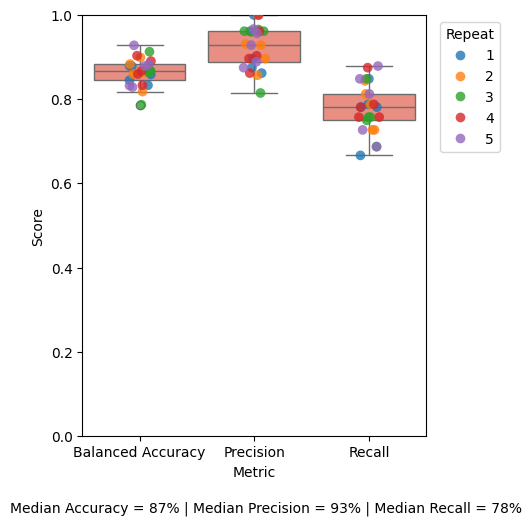

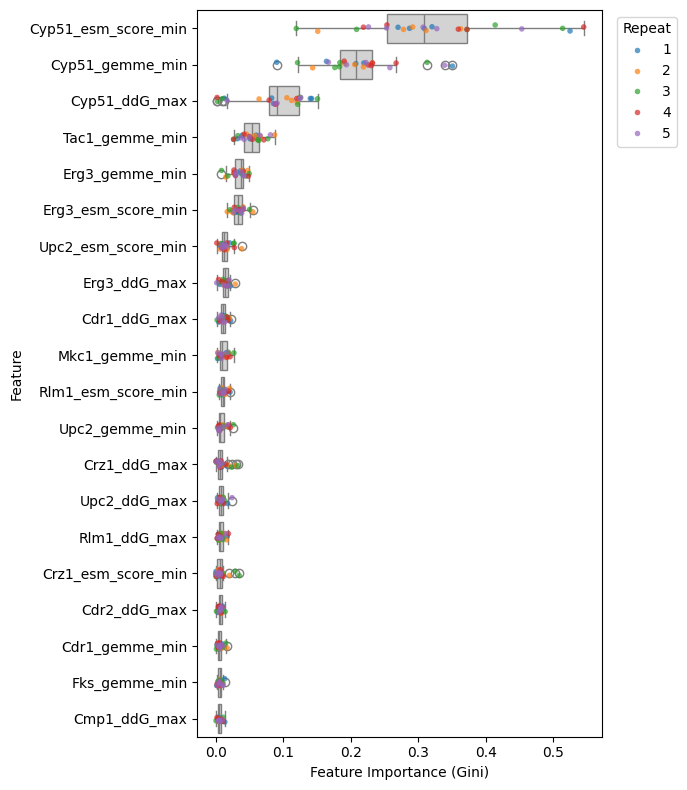

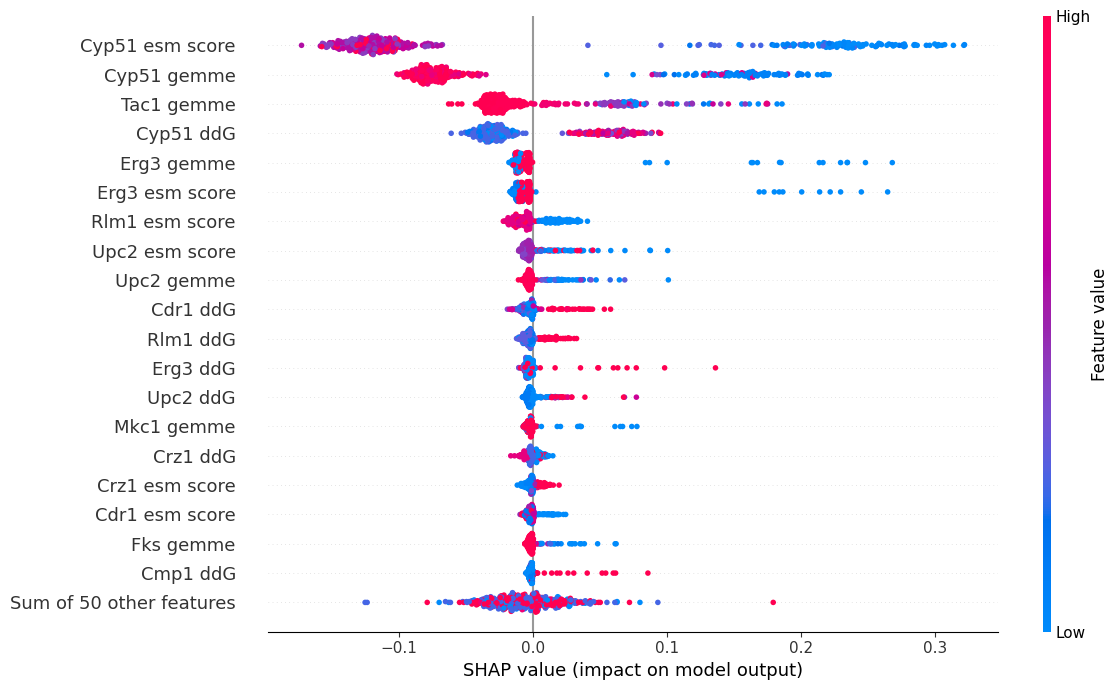

In [26]:
PCA_X_RF_VEP = wide_df.drop(columns=["SampleID", "rbin_flu", "pca_cluster_label"])
PCA_RF_VEP_shap_exp, PCA_RF_VEP_shap_df = plot_rf_results(PCA_RF_VEP_results_df, PCA_RF_VEP_feature_importances_df, PCA_RF_VEP_trained_models,
    PCA_X_RF_VEP, sample_ids=wide_df["SampleID"], top_features=20, plot_shap=True)

#### Group by Cluster et and stratify by Susceptibility

In [27]:
Group_PCA_RF_VEP_results_df, Group_PCA_RF_VEP_feature_importances_df, Group_PCA_RF_VEP_trained_models = rf_SGKF_nested_cv(wide_df=wide_df, target_col="rbin_flu",
    sample_col="SampleID", group_col="pca_cluster_label", drop_cols=["SampleID", "rbin_flu", "pca_cluster_label"], n_splits=5, n_repeats=5)


Stratification distribution:
rbin_flu
0    219
1    163
Name: count, dtype: int64

Number of groups:
7

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - Global 23
Repeat 5 - Fold 4 - Global 24
Repeat 5 - Fold 5 - Global 25

Best parameters:
   class_weight  

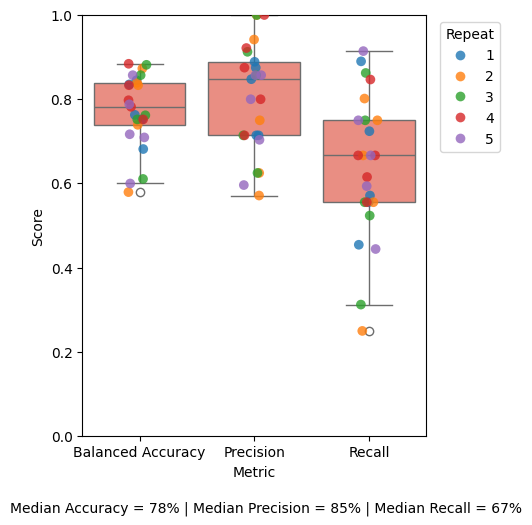

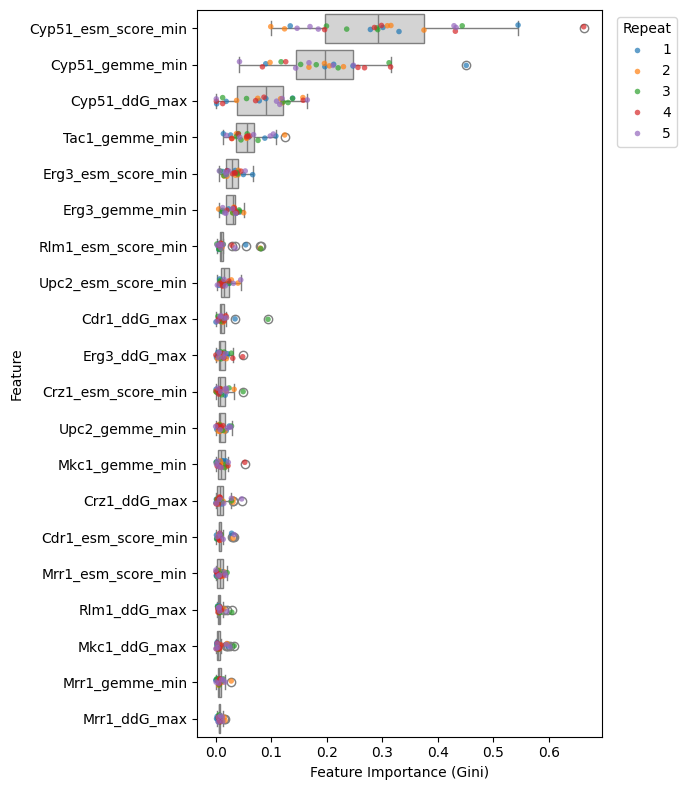

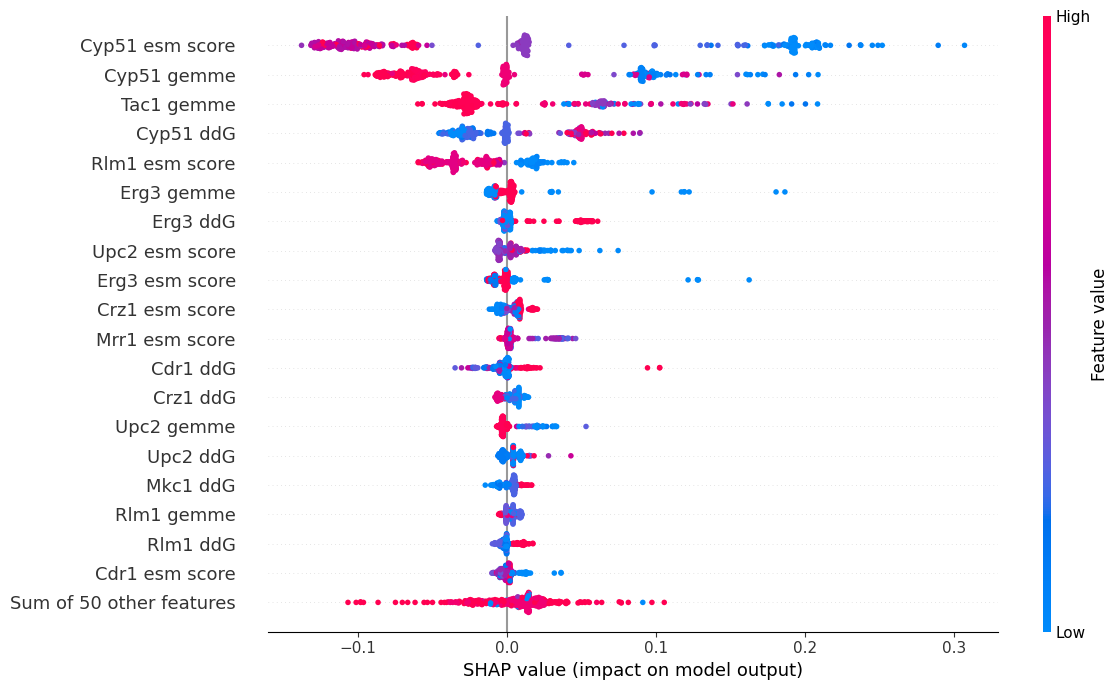

In [28]:
Group_PCA_X_RF_VEP = wide_df.drop(columns=["SampleID", "rbin_flu", "pca_cluster_label"])
Group_PCA_RF_VEP_shap_exp, Group_PCA_RF_VEP_shap_df = plot_rf_results(Group_PCA_RF_VEP_results_df, Group_PCA_RF_VEP_feature_importances_df, Group_PCA_RF_VEP_trained_models,
    Group_PCA_X_RF_VEP, sample_ids=wide_df["SampleID"], top_features=20, plot_shap=True)

## Use only FungAMR scores

#### Add FungAMR scores to the dataframe

In [29]:
df_flz_scores = pd.read_csv("strains_FLZ_scores_Nofilter.csv")
#Extract the column
col = df_flz_scores["Fluconazole_overall_score"]

#Create the new transformed score that is linear, because how confidence scores are currently encoded is not optimal for ML -->
#Low positive confidence scores (i.e BEST resistance confidence) will now have a high positive value (1 becomes 8, 2 becomes 7...)
#High negative confidence scores (i.e BEST susceptibility confidence) will now have a low negative value (-1 becomes -8, -2 becomes -7...)
#No score = 0 (which is in the middle since we cannot assume susceptibility or resistance)
df_flz_scores["Fluconazole_overall_score"] = col.apply(lambda x: (9 - x) if x > 0 else (-1 * (9 - abs(x))) if x < 0 else 0)
df_flz_scores

,Unnamed: 0,SampleID,rbin_flu,Fluconazole_overall_score
0,0,10,R,7.0
1,1,11,R,7.0
2,2,12,R,6.0
3,3,13,R,8.0
4,4,14,R,8.0
...,...,...,...,...
495,515,MYC-19-0375,R,-8.0
496,516,MYC-19-0376,R,1.0
497,517,MYC-19-0387,R,8.0
498,519,MYC-19-2,S,-8.0


In [30]:
#add to previous df
merged_df = wide_df.merge(df_flz_scores[["SampleID", "Fluconazole_overall_score"]],on="SampleID",how="left")
merged_df["Fluconazole_overall_score"] = merged_df["Fluconazole_overall_score"].fillna(0)
merged_df

,SampleID,pca_cluster_label,rbin_flu,Ben1_ddG_max,Cap1_ddG_max,Cdr1_ddG_max,Cdr2_ddG_max,Cmp1_ddG_max,Cnb1_ddG_max,Crz1_ddG_max,...,Mkk2_gemme_min,Mrr1_gemme_min,Mrr2_gemme_min,Rlm1_gemme_min,Rnr1_gemme_min,Rta2_gemme_min,Swi4_gemme_min,Tac1_gemme_min,Upc2_gemme_min,Fluconazole_overall_score
0,10,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595,7.0
1,11,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.782804,-0.145595,7.0
2,12,C13,R,2.66769,-0.00618,0.55438,1.26630,0.00000,0.0,1.31428,...,0.0,-0.706195,-1.606078,-1.273347,0.00000,0.000000,0.000000,-0.657407,-0.145595,6.0
3,13,C11,R,-1.22461,0.00000,0.10875,1.26630,-0.19399,0.0,0.00000,...,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.649549,-4.706017,8.0
4,14,C11,R,-1.22461,0.00000,0.10875,2.18000,-0.19399,0.0,0.00000,...,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.318087,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377,MYC-19-0374,C9,R,0.10707,0.00000,0.55438,3.04788,1.61226,0.0,1.67733,...,0.0,-0.250637,-0.469131,-1.380205,0.00000,-0.042900,-0.397886,-1.869529,0.000000,6.0
378,MYC-19-0375,C11,R,-1.22461,3.14543,0.10875,1.26630,-0.19399,0.0,0.41184,...,0.0,-0.070929,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-0.313256,-5.133083,-8.0
379,MYC-19-0387,C11,R,-1.22461,0.00000,1.07628,2.76699,-0.19399,0.0,0.00000,...,0.0,-0.308162,0.000000,-1.380205,0.00000,-0.045185,-6.634931,-1.869529,-4.706017,8.0
380,MYC-19-2,C6,S,-1.22461,0.00000,3.35436,17.90844,0.28188,0.0,0.06264,...,0.0,0.000000,-0.469131,-1.273347,-0.07259,0.000000,-2.835305,-0.260919,0.006437,-8.0


#### Stratify by Susceptibility and PCA clusters 

In [31]:
PCA_RF_FungAMR_results_df, PCA_RF_FungAMR_feature_importances_df, PCA_RF_FungAMR_trained_models = rf_SKF_nested_cv(merged_df, target_col="rbin_flu",
    drop_cols=['SampleID', 'pca_cluster_label', 'rbin_flu', 'Ben1_ddG_max',
       'Cap1_ddG_max', 'Cdr1_ddG_max', 'Cdr2_ddG_max', 'Cmp1_ddG_max',
       'Cnb1_ddG_max', 'Crz1_ddG_max', 'Cyp51_ddG_max', 'Erg1_ddG_max',
       'Erg2_ddG_max', 'Erg3_ddG_max', 'Fks_ddG_max', 'Fur1_ddG_max',
       'Mkc1_ddG_max', 'Mkk2_ddG_max', 'Mrr1_ddG_max', 'Mrr2_ddG_max',
       'Rlm1_ddG_max', 'Rnr1_ddG_max', 'Rta2_ddG_max', 'Swi4_ddG_max',
       'Tac1_ddG_max', 'Upc2_ddG_max', 'Ben1_esm_score_min',
       'Cap1_esm_score_min', 'Cdr1_esm_score_min', 'Cdr2_esm_score_min',
       'Cmp1_esm_score_min', 'Cnb1_esm_score_min', 'Crz1_esm_score_min',
       'Cyp51_esm_score_min', 'Erg1_esm_score_min', 'Erg2_esm_score_min',
       'Erg3_esm_score_min', 'Fks_esm_score_min', 'Fur1_esm_score_min',
       'Mkc1_esm_score_min', 'Mkk2_esm_score_min', 'Mrr1_esm_score_min',
       'Mrr2_esm_score_min', 'Rlm1_esm_score_min', 'Rnr1_esm_score_min',
       'Rta2_esm_score_min', 'Swi4_esm_score_min', 'Tac1_esm_score_min',
       'Upc2_esm_score_min', 'Ben1_gemme_min', 'Cap1_gemme_min',
       'Cdr1_gemme_min', 'Cdr2_gemme_min', 'Cmp1_gemme_min', 'Cnb1_gemme_min',
       'Crz1_gemme_min', 'Cyp51_gemme_min', 'Erg1_gemme_min', 'Erg2_gemme_min',
       'Erg3_gemme_min', 'Fks_gemme_min', 'Fur1_gemme_min', 'Mkc1_gemme_min',
       'Mkk2_gemme_min', 'Mrr1_gemme_min', 'Mrr2_gemme_min', 'Rlm1_gemme_min',
       'Rnr1_gemme_min', 'Rta2_gemme_min', 'Swi4_gemme_min', 'Tac1_gemme_min',
       'Upc2_gemme_min'], stratify_labels = ["rbin_flu","pca_cluster_label"], n_splits=5, n_repeats=5)

R_C11    100
S_C11     80
S_C1      39
S_C13     28
S_C9      28
S_C6      22
R_C9      21
S_C3      11
S_C14     11
R_C6      11
R_C1       9
R_C14      9
R_C13      8
R_C3       5
Name: count, dtype: int64

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - G

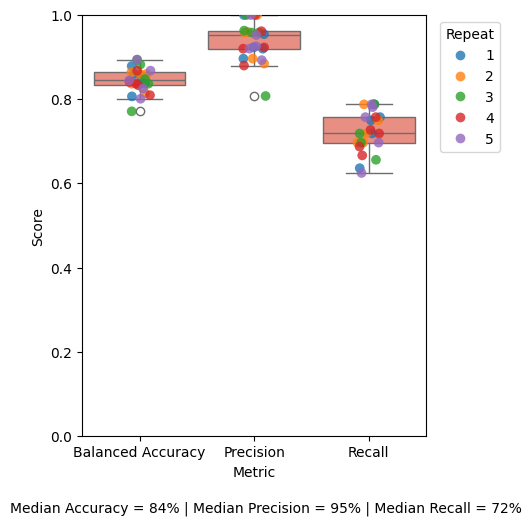

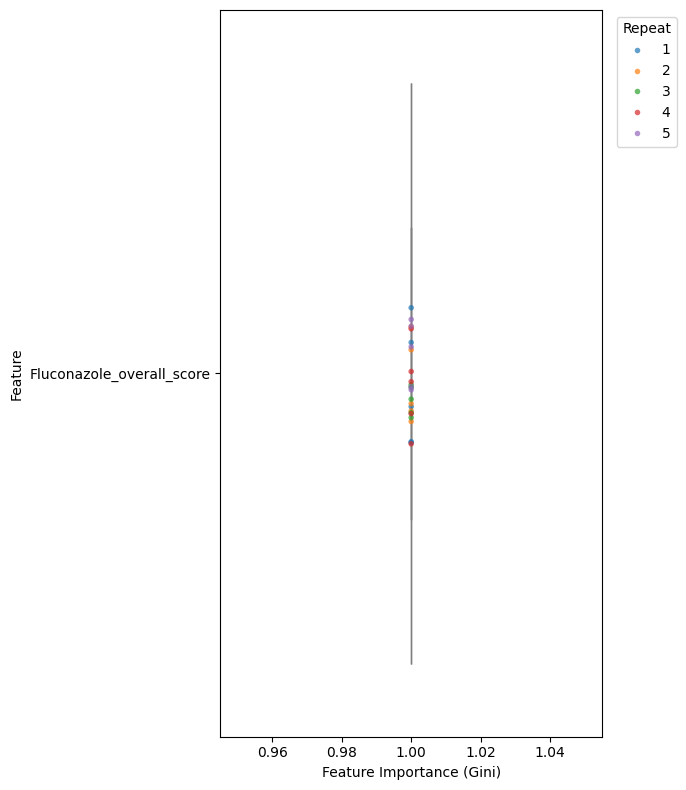

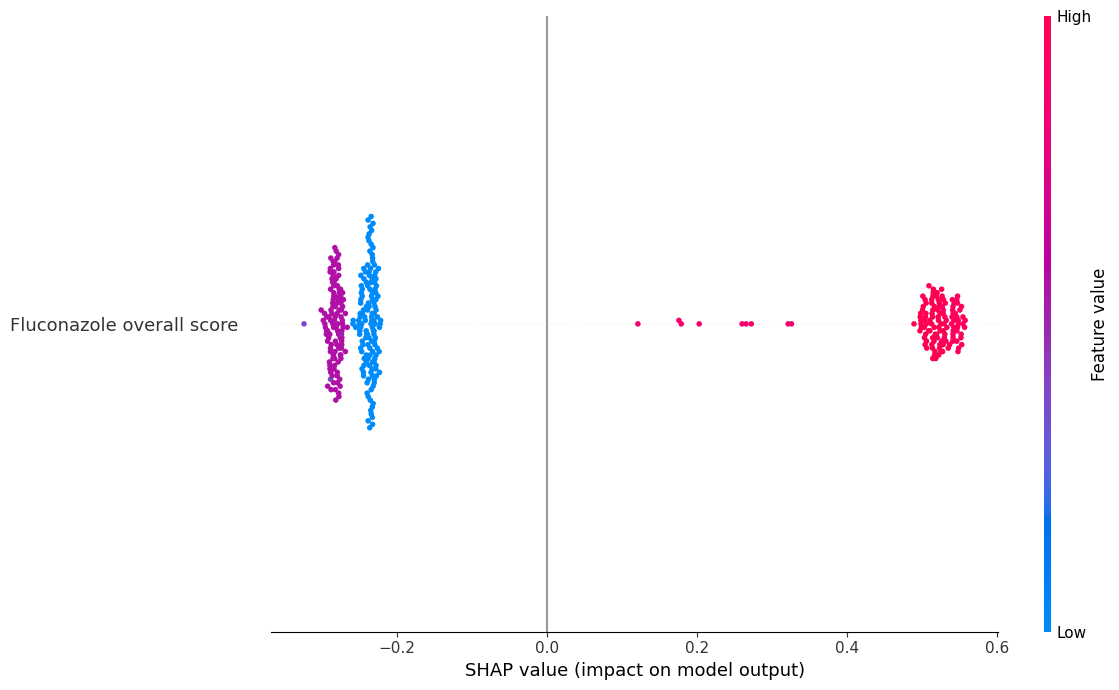

In [32]:
PCA_X_RF_FungAMR = merged_df.drop(columns=['SampleID', 'pca_cluster_label', 'rbin_flu', 'Ben1_ddG_max',
       'Cap1_ddG_max', 'Cdr1_ddG_max', 'Cdr2_ddG_max', 'Cmp1_ddG_max',
       'Cnb1_ddG_max', 'Crz1_ddG_max', 'Cyp51_ddG_max', 'Erg1_ddG_max',
       'Erg2_ddG_max', 'Erg3_ddG_max', 'Fks_ddG_max', 'Fur1_ddG_max',
       'Mkc1_ddG_max', 'Mkk2_ddG_max', 'Mrr1_ddG_max', 'Mrr2_ddG_max',
       'Rlm1_ddG_max', 'Rnr1_ddG_max', 'Rta2_ddG_max', 'Swi4_ddG_max',
       'Tac1_ddG_max', 'Upc2_ddG_max', 'Ben1_esm_score_min',
       'Cap1_esm_score_min', 'Cdr1_esm_score_min', 'Cdr2_esm_score_min',
       'Cmp1_esm_score_min', 'Cnb1_esm_score_min', 'Crz1_esm_score_min',
       'Cyp51_esm_score_min', 'Erg1_esm_score_min', 'Erg2_esm_score_min',
       'Erg3_esm_score_min', 'Fks_esm_score_min', 'Fur1_esm_score_min',
       'Mkc1_esm_score_min', 'Mkk2_esm_score_min', 'Mrr1_esm_score_min',
       'Mrr2_esm_score_min', 'Rlm1_esm_score_min', 'Rnr1_esm_score_min',
       'Rta2_esm_score_min', 'Swi4_esm_score_min', 'Tac1_esm_score_min',
       'Upc2_esm_score_min', 'Ben1_gemme_min', 'Cap1_gemme_min',
       'Cdr1_gemme_min', 'Cdr2_gemme_min', 'Cmp1_gemme_min', 'Cnb1_gemme_min',
       'Crz1_gemme_min', 'Cyp51_gemme_min', 'Erg1_gemme_min', 'Erg2_gemme_min',
       'Erg3_gemme_min', 'Fks_gemme_min', 'Fur1_gemme_min', 'Mkc1_gemme_min',
       'Mkk2_gemme_min', 'Mrr1_gemme_min', 'Mrr2_gemme_min', 'Rlm1_gemme_min',
       'Rnr1_gemme_min', 'Rta2_gemme_min', 'Swi4_gemme_min', 'Tac1_gemme_min',
       'Upc2_gemme_min'])
PCA_RF_FungAMR_shap_exp, PCA_RF_FungAMR_shap_df = plot_rf_results(PCA_RF_FungAMR_results_df, PCA_RF_FungAMR_feature_importances_df, PCA_RF_FungAMR_trained_models,
    PCA_X_RF_FungAMR, sample_ids=merged_df["SampleID"], top_features=20, plot_shap=True)

#### Group by Cluster et and stratify by Susceptibility

In [33]:
Group_PCA_RF_FungAMR_results_df, Group_PCA_RF_FungAMR_feature_importances_df, Group_PCA_RF_FungAMR_trained_models = rf_SGKF_nested_cv(wide_df=merged_df, target_col="rbin_flu",
    sample_col="SampleID", group_col="pca_cluster_label", drop_cols=['SampleID', 'pca_cluster_label', 'rbin_flu', 'Ben1_ddG_max',
       'Cap1_ddG_max', 'Cdr1_ddG_max', 'Cdr2_ddG_max', 'Cmp1_ddG_max',
       'Cnb1_ddG_max', 'Crz1_ddG_max', 'Cyp51_ddG_max', 'Erg1_ddG_max',
       'Erg2_ddG_max', 'Erg3_ddG_max', 'Fks_ddG_max', 'Fur1_ddG_max',
       'Mkc1_ddG_max', 'Mkk2_ddG_max', 'Mrr1_ddG_max', 'Mrr2_ddG_max',
       'Rlm1_ddG_max', 'Rnr1_ddG_max', 'Rta2_ddG_max', 'Swi4_ddG_max',
       'Tac1_ddG_max', 'Upc2_ddG_max', 'Ben1_esm_score_min',
       'Cap1_esm_score_min', 'Cdr1_esm_score_min', 'Cdr2_esm_score_min',
       'Cmp1_esm_score_min', 'Cnb1_esm_score_min', 'Crz1_esm_score_min',
       'Cyp51_esm_score_min', 'Erg1_esm_score_min', 'Erg2_esm_score_min',
       'Erg3_esm_score_min', 'Fks_esm_score_min', 'Fur1_esm_score_min',
       'Mkc1_esm_score_min', 'Mkk2_esm_score_min', 'Mrr1_esm_score_min',
       'Mrr2_esm_score_min', 'Rlm1_esm_score_min', 'Rnr1_esm_score_min',
       'Rta2_esm_score_min', 'Swi4_esm_score_min', 'Tac1_esm_score_min',
       'Upc2_esm_score_min', 'Ben1_gemme_min', 'Cap1_gemme_min',
       'Cdr1_gemme_min', 'Cdr2_gemme_min', 'Cmp1_gemme_min', 'Cnb1_gemme_min',
       'Crz1_gemme_min', 'Cyp51_gemme_min', 'Erg1_gemme_min', 'Erg2_gemme_min',
       'Erg3_gemme_min', 'Fks_gemme_min', 'Fur1_gemme_min', 'Mkc1_gemme_min',
       'Mkk2_gemme_min', 'Mrr1_gemme_min', 'Mrr2_gemme_min', 'Rlm1_gemme_min',
       'Rnr1_gemme_min', 'Rta2_gemme_min', 'Swi4_gemme_min', 'Tac1_gemme_min',
       'Upc2_gemme_min'], n_splits=5, n_repeats=5)


Stratification distribution:
rbin_flu
0    219
1    163
Name: count, dtype: int64

Number of groups:
7

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - Global 23
Repeat 5 - Fold 4 - Global 24
Repeat 5 - Fold 5 - Global 25

Best parameters:
   class_weight  

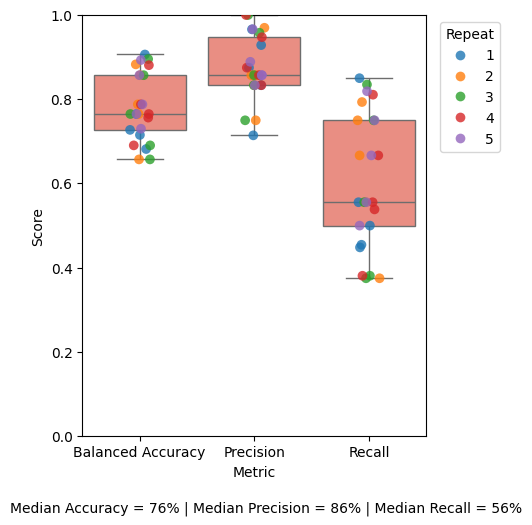

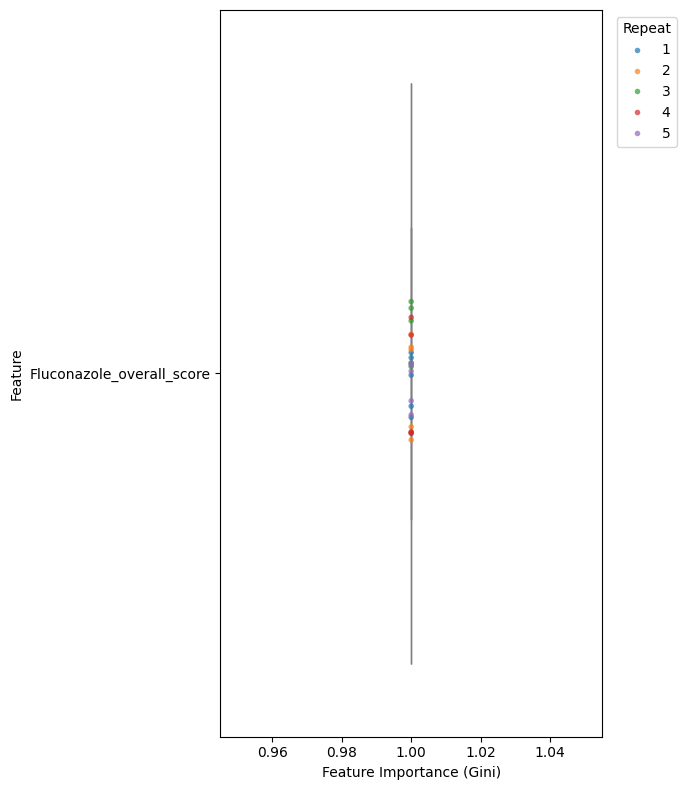

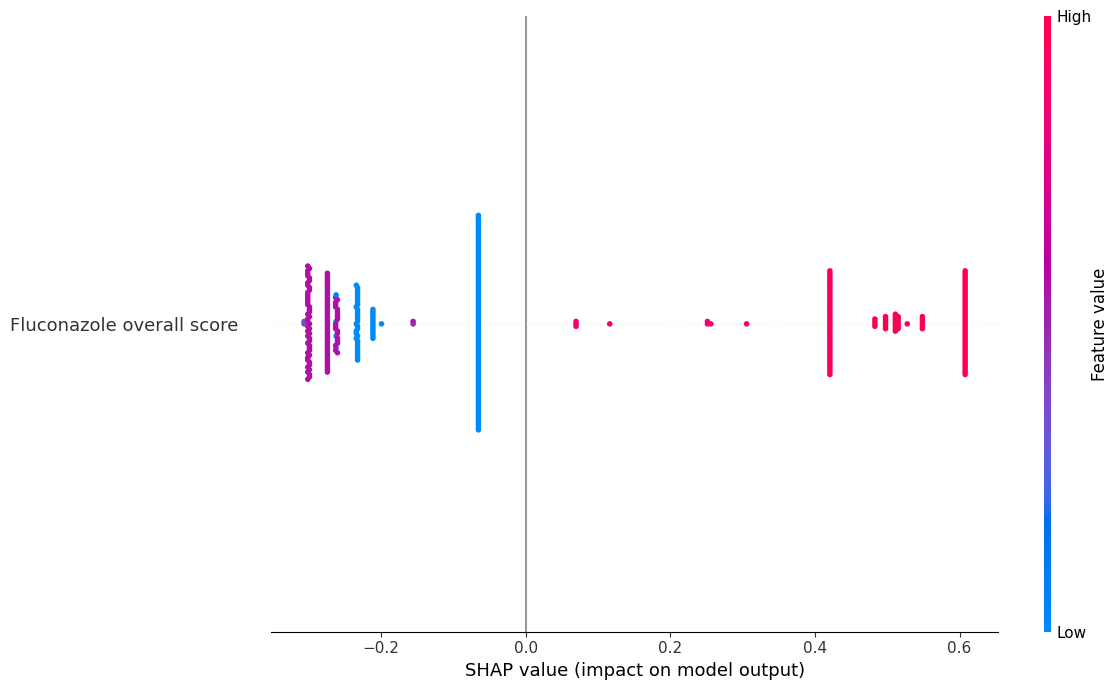

In [34]:
Group_PCA_X_RF_FungAMR = merged_df.drop(columns=['SampleID', 'pca_cluster_label', 'rbin_flu', 'Ben1_ddG_max',
       'Cap1_ddG_max', 'Cdr1_ddG_max', 'Cdr2_ddG_max', 'Cmp1_ddG_max',
       'Cnb1_ddG_max', 'Crz1_ddG_max', 'Cyp51_ddG_max', 'Erg1_ddG_max',
       'Erg2_ddG_max', 'Erg3_ddG_max', 'Fks_ddG_max', 'Fur1_ddG_max',
       'Mkc1_ddG_max', 'Mkk2_ddG_max', 'Mrr1_ddG_max', 'Mrr2_ddG_max',
       'Rlm1_ddG_max', 'Rnr1_ddG_max', 'Rta2_ddG_max', 'Swi4_ddG_max',
       'Tac1_ddG_max', 'Upc2_ddG_max', 'Ben1_esm_score_min',
       'Cap1_esm_score_min', 'Cdr1_esm_score_min', 'Cdr2_esm_score_min',
       'Cmp1_esm_score_min', 'Cnb1_esm_score_min', 'Crz1_esm_score_min',
       'Cyp51_esm_score_min', 'Erg1_esm_score_min', 'Erg2_esm_score_min',
       'Erg3_esm_score_min', 'Fks_esm_score_min', 'Fur1_esm_score_min',
       'Mkc1_esm_score_min', 'Mkk2_esm_score_min', 'Mrr1_esm_score_min',
       'Mrr2_esm_score_min', 'Rlm1_esm_score_min', 'Rnr1_esm_score_min',
       'Rta2_esm_score_min', 'Swi4_esm_score_min', 'Tac1_esm_score_min',
       'Upc2_esm_score_min', 'Ben1_gemme_min', 'Cap1_gemme_min',
       'Cdr1_gemme_min', 'Cdr2_gemme_min', 'Cmp1_gemme_min', 'Cnb1_gemme_min',
       'Crz1_gemme_min', 'Cyp51_gemme_min', 'Erg1_gemme_min', 'Erg2_gemme_min',
       'Erg3_gemme_min', 'Fks_gemme_min', 'Fur1_gemme_min', 'Mkc1_gemme_min',
       'Mkk2_gemme_min', 'Mrr1_gemme_min', 'Mrr2_gemme_min', 'Rlm1_gemme_min',
       'Rnr1_gemme_min', 'Rta2_gemme_min', 'Swi4_gemme_min', 'Tac1_gemme_min',
       'Upc2_gemme_min'])
Group_PCA_RF_FungAMR_shap_exp, Group_PCA_RF_FungAMR_shap_df = plot_rf_results(Group_PCA_RF_FungAMR_results_df, Group_PCA_RF_FungAMR_feature_importances_df, Group_PCA_RF_FungAMR_trained_models,
    Group_PCA_X_RF_FungAMR, sample_ids=merged_df["SampleID"], top_features=20, plot_shap=True)

## VEPs + FungAMR

#### Stratify by Susceptibility and PCA clusters 

In [35]:
PCA_RF_VEP_FungAMR_results_df, PCA_RF_VEP_FungAMR_feature_importances_df, PCA_RF_VEP_FungAMR_trained_models = rf_SKF_nested_cv(wide_df=merged_df, target_col="rbin_flu",
    drop_cols=["SampleID", "rbin_flu", "pca_cluster_label"], stratify_labels = ["rbin_flu","pca_cluster_label"], n_splits=5, n_repeats=5)

R_C11    100
S_C11     80
S_C1      39
S_C13     28
S_C9      28
S_C6      22
R_C9      21
S_C3      11
S_C14     11
R_C6      11
R_C1       9
R_C14      9
R_C13      8
R_C3       5
Name: count, dtype: int64

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - G

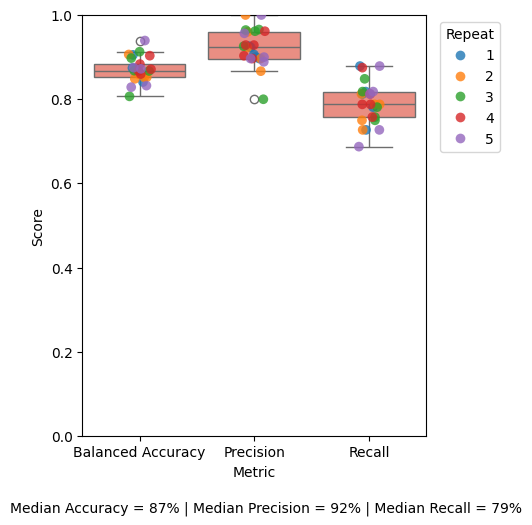

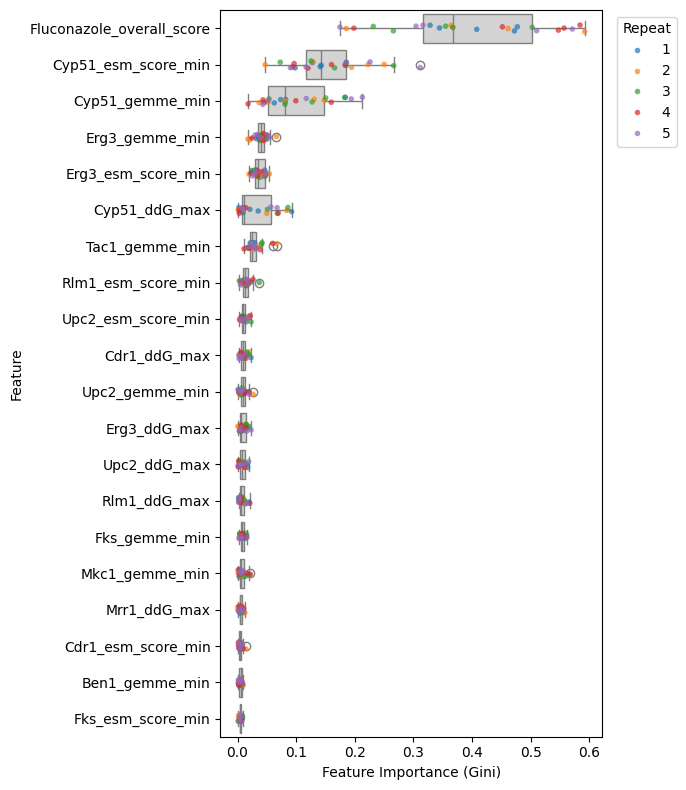

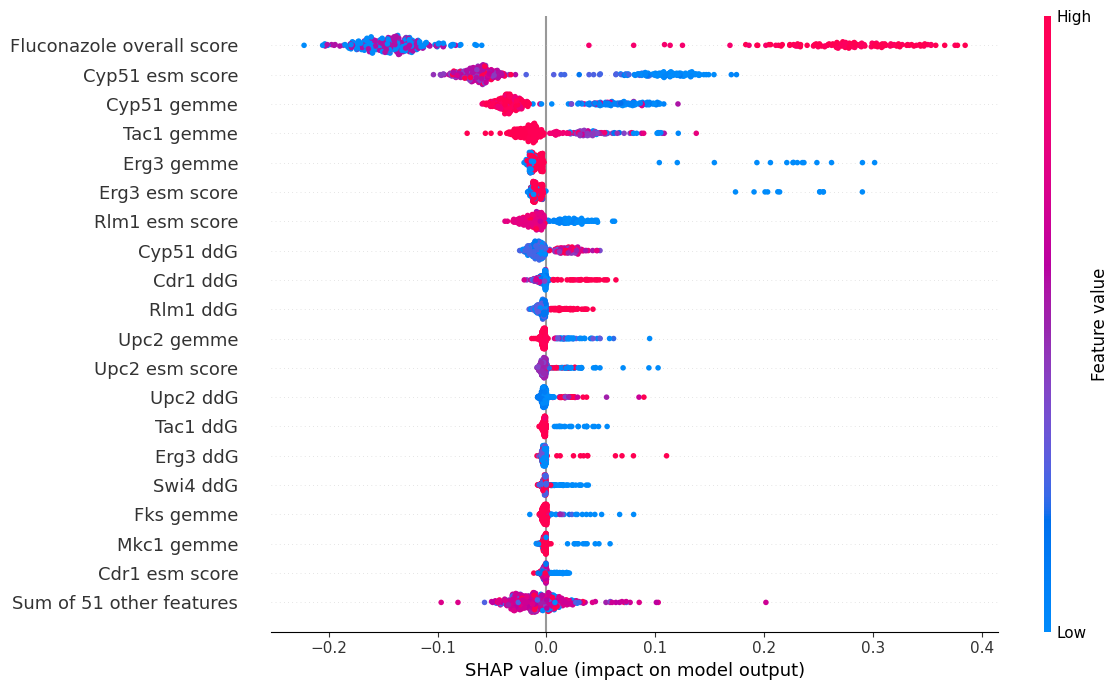

In [36]:
PCA_X_RF_VEP_FungAMR = merged_df.drop(columns=["SampleID", "rbin_flu", "pca_cluster_label"])
PCA_RF_VEP_FungAMR_shap_exp, PCA_RF_VEP_FungAMR_shap_df = plot_rf_results(PCA_RF_VEP_FungAMR_results_df, PCA_RF_VEP_FungAMR_feature_importances_df, PCA_RF_VEP_FungAMR_trained_models,
    PCA_X_RF_VEP_FungAMR, sample_ids=merged_df["SampleID"], top_features=20, plot_shap=True)

#### Group by Cluster et and stratify by Susceptibility

In [37]:
Group_PCA_RF_VEP_FungAMR_results_df, Group_PCA_RF_VEP_FungAMR_feature_importances_df, Group_PCA_RF_VEP_FungAMR_trained_models = rf_SGKF_nested_cv(wide_df=merged_df, target_col="rbin_flu",
    sample_col="SampleID", group_col="pca_cluster_label", drop_cols=["SampleID", "rbin_flu", "pca_cluster_label"], n_splits=5, n_repeats=5)


Stratification distribution:
rbin_flu
0    219
1    163
Name: count, dtype: int64

Number of groups:
7

Repeat 1/5  seed = 377
Repeat 1 - Fold 1 - Global 1
Repeat 1 - Fold 2 - Global 2
Repeat 1 - Fold 3 - Global 3
Repeat 1 - Fold 4 - Global 4
Repeat 1 - Fold 5 - Global 5

Repeat 2/5  seed = 479
Repeat 2 - Fold 1 - Global 6
Repeat 2 - Fold 2 - Global 7
Repeat 2 - Fold 3 - Global 8
Repeat 2 - Fold 4 - Global 9
Repeat 2 - Fold 5 - Global 10

Repeat 3/5  seed = 582
Repeat 3 - Fold 1 - Global 11
Repeat 3 - Fold 2 - Global 12
Repeat 3 - Fold 3 - Global 13
Repeat 3 - Fold 4 - Global 14
Repeat 3 - Fold 5 - Global 15

Repeat 4/5  seed = 686
Repeat 4 - Fold 1 - Global 16
Repeat 4 - Fold 2 - Global 17
Repeat 4 - Fold 3 - Global 18
Repeat 4 - Fold 4 - Global 19
Repeat 4 - Fold 5 - Global 20

Repeat 5/5  seed = 791
Repeat 5 - Fold 1 - Global 21
Repeat 5 - Fold 2 - Global 22
Repeat 5 - Fold 3 - Global 23
Repeat 5 - Fold 4 - Global 24
Repeat 5 - Fold 5 - Global 25

Best parameters:
   class_weight  

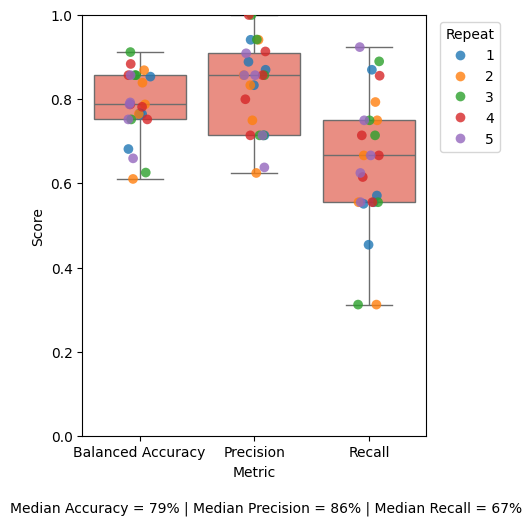

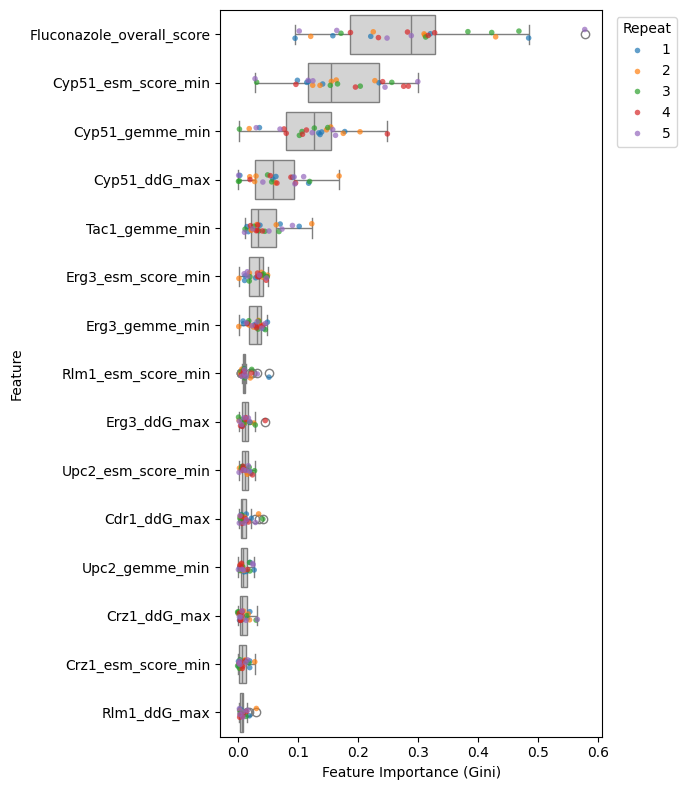

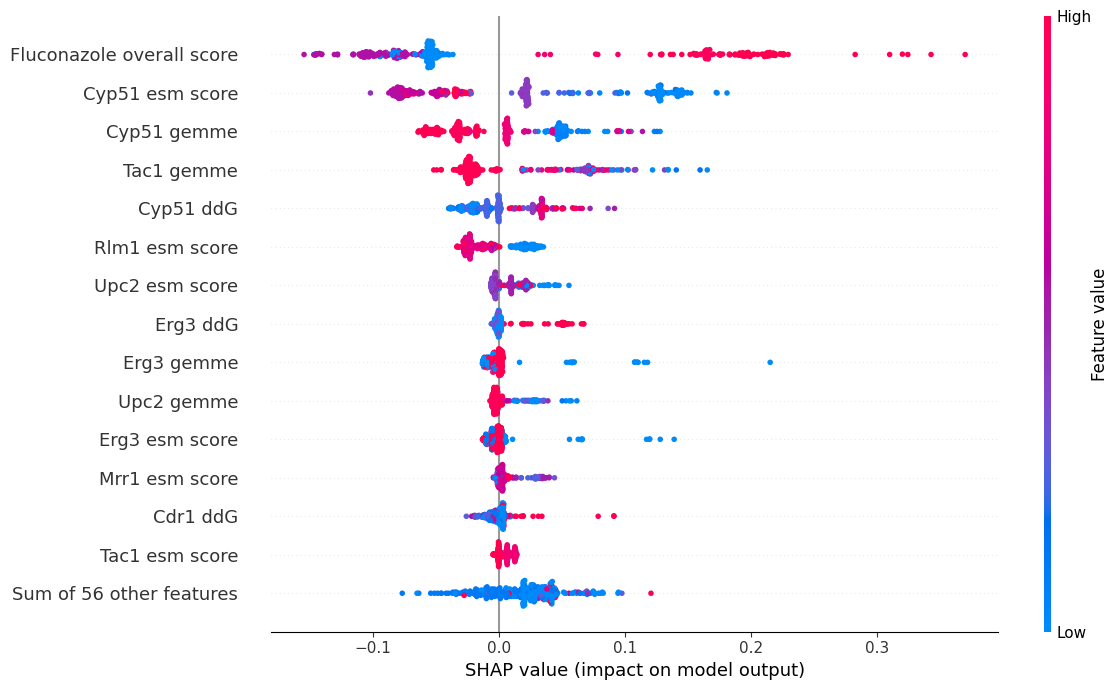

In [38]:
Group_PCA_X_RF_VEP_FungAMR = merged_df.drop(columns=["SampleID", "rbin_flu", "pca_cluster_label"])
Group_PCA_RF_VEP_FungAMR_shap_exp, Group_PCA_RF_VEP_FungAMR_shap_df = plot_rf_results(Group_PCA_RF_VEP_FungAMR_results_df, Group_PCA_RF_VEP_FungAMR_feature_importances_df, Group_PCA_RF_VEP_FungAMR_trained_models,
    Group_PCA_X_RF_VEP_FungAMR, sample_ids=merged_df["SampleID"], top_features=15, plot_shap=True)

##The shap plot here is the one in figure 6 B

## Graph comparing all for figure 6 A

C:\Users\camil\AppData\Local\Temp\ipykernel_6280\2672293507.py:54: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=panel_data,
C:\Users\camil\AppData\Local\Temp\ipykernel_6280\2672293507.py:54: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=panel_data,


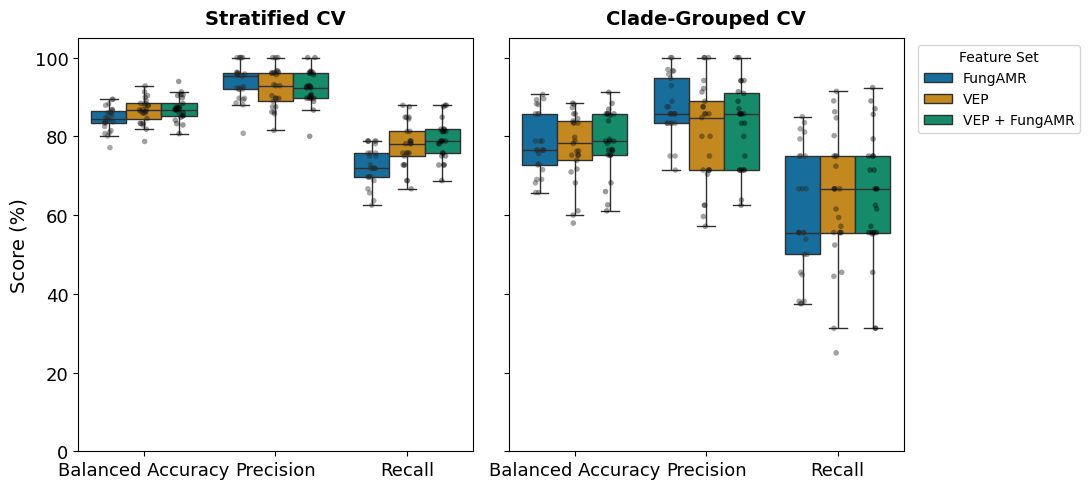

In [39]:
strategy_groups = {"Stratified CV": {"FungAMR": PCA_RF_FungAMR_results_df,
        "VEP": PCA_RF_VEP_results_df,
        "VEP + FungAMR": PCA_RF_VEP_FungAMR_results_df},
    "Clade-Grouped CV": {"FungAMR": Group_PCA_RF_FungAMR_results_df,
        "VEP": Group_PCA_RF_VEP_results_df,
        "VEP + FungAMR": Group_PCA_RF_VEP_FungAMR_results_df}}

metrics = ["Balanced Accuracy", "Precision", "Recall"]

dfs = []

for strategy_name, feature_sets in strategy_groups.items():

    for feature_set_name, df in feature_sets.items():

        temp_df = df[metrics].copy()

        temp_df["Strategy"] = strategy_name
        temp_df["Feature Set"] = feature_set_name

        temp_df["Fold"] = df["global_fold"]

        dfs.append(temp_df)

combined_df = pd.concat(dfs, ignore_index=True)

melted_df = pd.melt(combined_df,
    id_vars=["Strategy", "Feature Set"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",)

#Scores in %
melted_df["Scoreper"] = melted_df["Score"] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

palette = sns.color_palette("colorblind", 3)

for idx, strategy_name in enumerate(strategy_groups.keys()):
    ax = axes[idx]
    panel_data = melted_df[melted_df["Strategy"] == strategy_name]

    #Boxplot base
    sns.boxplot(data=panel_data,
        x="Metric",
        y="Scoreper",
        hue="Feature Set", 
        palette=palette,
        showfliers = False,
        ax=ax)

    #Individual fold points 
    sns.stripplot(data=panel_data,
        x="Metric",
        y="Scoreper",
        hue="Feature Set",
        dodge=True,
        color="black",
        alpha=0.4,
        jitter=0.1,
        size=4,
        ax=ax)

    ax.set_title(strategy_name, fontsize=14, fontweight="bold", pad=10)
    ax.set_ylim(0, 105)
    ax.set_xlabel("")
    ax.set_ylabel("Score (%)", fontsize=14)

    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

    #remove duplicated legends
    if idx == 1:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles[:3],
            labels[:3],
            title="Feature Set",
            bbox_to_anchor=(1.02, 1),
            loc="upper left")
    else:
        ax.get_legend().remove()

plt.tight_layout()
plt.rcParams['svg.fonttype'] = 'none'
plt.savefig("metrics_final.svg", bbox_inches="tight")
plt.show()

In [47]:
#get a table with the median and IQRs 

metrics = ["Balanced Accuracy", "Precision", "Recall"]

def median_iqr(x):
    median = x.median()
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    return f"{median:.1%} (IQR {q1:.1%}–{q3:.1%})"

summary_table = (combined_df.groupby(["Strategy", "Feature Set"])[metrics].agg(median_iqr))

summary_table

Balanced Accuracy  \
Strategy         Feature Set                              
Clade-Grouped CV FungAMR        76.5% (IQR 72.7%–85.7%)   
                 VEP            78.2% (IQR 73.9%–83.9%)   
                 VEP + FungAMR  78.8% (IQR 75.2%–85.7%)   
Stratified CV    FungAMR        84.5% (IQR 83.3%–86.4%)   
                 VEP            86.7% (IQR 84.5%–88.4%)   
                 VEP + FungAMR  86.8% (IQR 85.2%–88.4%)   

                                              Precision  \
Strategy         Feature Set                              
Clade-Grouped CV FungAMR        85.7% (IQR 83.3%–94.7%)   
                 VEP            84.8% (IQR 71.4%–88.9%)   
                 VEP + FungAMR  85.7% (IQR 71.4%–90.9%)   
Stratified CV    FungAMR        95.2% (IQR 92.0%–96.2%)   
                 VEP            92.9% (IQR 88.9%–96.2%)   
                 VEP + FungAMR  92.3% (IQR 89.7%–96.0%)   

                                                 Recall  
Strategy         Feature Set                             
Clade-Grouped CV FungAMR        55.6% (IQR 50.0%–75.0%)  
                 VEP            66.7% (IQR 55.6%–75.0%)  
                 VEP + FungAMR  66.7% (IQR 55.6%–75.0%)  
Stratified CV    FungAMR        71.9% (IQR 69.7%–75.8%)  
                 VEP            78.1% (IQR 75.0%–81.2%)  
                 VEP + FungAMR  78.8% (IQR 75.8%–81.8%)